Nama : Tara Tabriza Rachman
NIM : 24031554107
Kelas : 2024A

### **1.2 Mempelajari Penggunaan Driver Neo4J**

In [99]:
import neo4j
from neo4j import GraphDatabase, RoutingControl

print("Versi Neo4j:", neo4j.__version__)
print("RoutingControl:", RoutingControl.READ)

Versi Neo4j: 5.28.8
RoutingControl: RoutingControl.READ


In [100]:
URI = "neo4j://127.0.0.1:7687"
USERNAME = "neo4j"
PASSWORD = "taratabriza20"

driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

driver.verify_connectivity()
print("Python berhasil terhubung ke Neo4j!")


Python berhasil terhubung ke Neo4j!


In [101]:
result = driver.execute_query(
    "SHOW DATABASES",
    database_="system"
)

for record in result.records:
    print(record["name"], "-", record["currentStatus"])

movie - online
neo4j - online
retailrocket - online
system - online


In [102]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        """
        MERGE (a:Person {name: $name})
        MERGE (friend:Person {name: $friend_name})
        MERGE (a)-[:KNOWS]->(friend)
        """,
        name=name,
        friend_name=friend_name,
        database_="neo4j"
    )


def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        """
        MATCH (a:Person)-[:KNOWS]->(friend)
        WHERE a.name = $name
        RETURN friend.name AS friend
        ORDER BY friend
        """,
        name=name,
        database_="neo4j",
        routing_=RoutingControl.READ
    )

    for record in records:
        print(record["friend"])


add_friend(driver, "Arthur", "Guinevere")
add_friend(driver, "Arthur", "Lancelot")
add_friend(driver, "Arthur", "Merlin")

print("Teman Arthur:")
print_friends(driver, "Arthur")


Teman Arthur:
Guinevere
Lancelot
Merlin


**Pendahuluan (*Checkpoint*)**
1. Apa nama database yang digunakan pada tutorial ini?
> Database yang digunakan pada tutorial adalah **neo4j**, sesuai dengan parameter **database_=”neo4j”** pada fungsi **add_friend()** dan **print_friends()**
2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!
> Ketika ingin mengakses database lain dalam satu instance Neo4j, nama database dapat ditentukan melalui parameter **database_** pada fungsi **execute_query()** menggunakan Python Driver. Selain itu, perintah Cypher dapat digunakan untuk membuat, membaca, memperbarui, dan menghapus data, seperti **CREATE**, **MATCH**, **SET**, dan **DELETE**.
3. Apa jenis graf pertemanan yang telah dibuat di sini?
> Graf pertemanan yang dibuat adalah graf berarah (*directed graph*), karena relasi **KNOWS** dibuat dari node **Arthur** menuju node temannya, misalnya **(a)-[:KNOWS]->(friend)**. Relasi tersebut memiliki arah dari orang yang mengenal menuju orang yang dikenal.


### **2.1 Wrangling dan EDA**

In [103]:
import pandas as pd

events = pd.read_csv("events.csv")
# Menampilkan 5 baris pertama
display(events.head())

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [104]:
print("Ukuran dataset:", events.shape)

print("\nNama kolom:")
print(events.columns.tolist())

print("\nJenis aktivitas:")
print(events["event"].value_counts())

Ukuran dataset: (2756101, 5)

Nama kolom:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

Jenis aktivitas:
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


In [105]:
# Mengubah timestamp Unix milidetik menjadi tanggal
events["datetime"] = pd.to_datetime(
    events["timestamp"],
    unit="ms",
    utc=True
)

# Memeriksa rentang tanggal
print("Tanggal paling awal:", events["datetime"].min())
print("Tanggal paling akhir:", events["datetime"].max())

# Menampilkan contoh hasil konversi
display(events[["timestamp", "datetime", "event"]].head())

Tanggal paling awal: 2015-05-03 03:00:04.384000+00:00
Tanggal paling akhir: 2015-09-18 02:59:47.788000+00:00


,timestamp,datetime,event
0,1433221332117,2015-06-02 05:02:12.117000+00:00,view
1,1433224214164,2015-06-02 05:50:14.164000+00:00,view
2,1433221999827,2015-06-02 05:13:19.827000+00:00,view
3,1433221955914,2015-06-02 05:12:35.914000+00:00,view
4,1433221337106,2015-06-02 05:02:17.106000+00:00,view


1. **Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yg dipilih per individu tidak boleh sama dalam 1 kelas.**


In [106]:
# Menentukan batas periode training dan testing
p1_start = pd.Timestamp("2015-06-10", tz="UTC")
p1_end   = pd.Timestamp("2015-07-26", tz="UTC")

p2_start = pd.Timestamp("2015-07-26", tz="UTC")
p2_end   = pd.Timestamp("2015-09-11", tz="UTC")

# Memisahkan data berdasarkan tanggal
p1 = events[
    (events["datetime"] >= p1_start) &
    (events["datetime"] < p1_end)
].copy()

p2 = events[
    (events["datetime"] >= p2_start) &
    (events["datetime"] < p2_end)
].copy()

print("Jumlah data P1 (Training):", len(p1))
print("Jumlah data P2 (Testing):", len(p2))


Jumlah data P1 (Training): 970948
Jumlah data P2 (Testing): 885070


2. **Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!**

In [107]:
# Menyimpan data training dan testing
p1.drop(columns=["datetime"]).to_csv(
    "events_P1_training.csv",
    index=False
)

p2.drop(columns=["datetime"]).to_csv(
    "events_P2_testing.csv",
    index=False
)

print("File P1 dan P2 berhasil disimpan!")

File P1 dan P2 berhasil disimpan!


#### **Melakukan proses Impor Data dari RetailRocket ke Database Neo4J**

In [108]:
import pandas as pd

events = pd.read_csv("events_P1_training.csv")

print("Jumlah baris:", len(events))
print("Kolom:", events.columns.tolist())
display(events.head())

Jumlah baris: 970948
Kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']


,timestamp,visitorid,event,itemid,transactionid
0,1433904204857,963925,view,325772,NaN
1,1433904651539,228486,view,364594,NaN
2,1433906643139,1037925,view,284661,NaN
3,1433906860642,621375,view,96924,NaN
4,1433906643420,526972,view,283115,NaN


In [109]:
%pip install tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [110]:
import math
import pandas as pd
from tqdm.auto import tqdm

# File training yang sudah difilter pada periode P1
csv_file_path = "events_P1_training.csv"
batch_size = 1000

# Membaca data untuk pemeriksaan awal
events = pd.read_csv(
    csv_file_path,
    dtype={"transactionid": "string"}
)

print("Jumlah baris:", len(events))
print("Kolom:", events.columns.tolist())
display(events.head())

print("\nJumlah event:")
display(events["event"].value_counts())


Jumlah baris: 970948
Kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']


,timestamp,visitorid,event,itemid,transactionid
0,1433904204857,963925,view,325772,<NA>
1,1433904651539,228486,view,364594,<NA>
2,1433906643139,1037925,view,284661,<NA>
3,1433906860642,621375,view,96924,<NA>
4,1433906643420,526972,view,283115,<NA>



Jumlah event:


event
view           938482
addtocart       24423
transaction      8043
Name: count, dtype: int64

In [111]:
%pip install tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [112]:
def import_batch(tx, batch):
    query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    CALL (v, i, row) {
        WITH v, i, row
        WHERE row.event = 'view'
        MERGE (v)-[r:VIEWED {eventId: row.event_id}]->(i)
        SET r.timestamp = row.timestamp
    }

    CALL (v, i, row) {
        WITH v, i, row
        WHERE row.event = 'addtocart'
        MERGE (v)-[r:ADDED_TO_CART {eventId: row.event_id}]->(i)
        SET r.timestamp = row.timestamp
    }

    CALL (v, i, row) {
        WITH v, i, row
        WHERE row.event = 'transaction'
        MERGE (v)-[r:BOUGHT {eventId: row.event_id}]->(i)
        SET r.timestamp = row.timestamp,
            r.transactionId = row.transactionid
    }
    """
    tx.run(query, batch=batch)

print("Fungsi import_batch siap digunakan.")


Fungsi import_batch siap digunakan.


In [113]:

# Constraint agar ID node tidak terduplikasi
driver.execute_query(
    """
    CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
    FOR (v:Visitor)
    REQUIRE v.visitorId IS UNIQUE
    """,
    database_="retailrocket"
)

driver.execute_query(
    """
    CREATE CONSTRAINT item_id_unique IF NOT EXISTS
    FOR (i:Item)
    REQUIRE i.itemId IS UNIQUE
    """,
    database_="retailrocket"
)

total_rows = len(events)
total_chunks = math.ceil(total_rows / batch_size)

with driver.session(database="retailrocket") as session:
    for chunk in tqdm(
        pd.read_csv(
            csv_file_path,
            chunksize=batch_size,
            dtype={"transactionid": "string"}
        ),
        total=total_chunks,
        desc="Mengimpor data P1"
    ):
        # Nomor baris CSV yang stabil untuk identitas event
        chunk["event_id"] = chunk.index.astype(str)

        # Pastikan tipe data ID konsisten
        chunk["visitorid"] = chunk["visitorid"].astype("int64")
        chunk["itemid"] = chunk["itemid"].astype("int64")
        chunk["timestamp"] = chunk["timestamp"].astype("int64")
        chunk["transactionid"] = chunk["transactionid"].fillna("")

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Proses impor data P1 selesai.")


Mengimpor data P1: 100%|██████████| 971/971 [04:03<00:00,  3.99it/s]

Proses impor data P1 selesai.


In [114]:
result, _, _ = driver.execute_query(
    """
    MATCH (v:Visitor)
    WITH count(v) AS jumlah_visitor
    MATCH (i:Item)
    WITH jumlah_visitor, count(i) AS jumlah_item
    MATCH ()-[r:VIEWED|ADDED_TO_CART|BOUGHT]->()
    RETURN
        jumlah_visitor,
        jumlah_item,
        count(r) AS jumlah_relasi
    """,
    database_="retailrocket"
)

print("Jumlah Visitor:", result[0]["jumlah_visitor"])
print("Jumlah Item:", result[0]["jumlah_item"])
print("Jumlah relasi event:", result[0]["jumlah_relasi"])

Jumlah Visitor: 509115
Jumlah Item: 149709
Jumlah relasi event: 970948


3. **Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!**

In [115]:
# Mengambil jumlah setiap jenis node dari Neo4j
result, _, _ = driver.execute_query(
    """
    MATCH (n)
    WHERE n:Visitor OR n:Item
    RETURN labels(n) AS jenis_node, count(n) AS jumlah
    ORDER BY jenis_node
    """,
    database_="retailrocket"
)

print("Komposisi Node:")
for row in result:
    print(f"{row['jenis_node']}: {row['jumlah']}")

Komposisi Node:
['Item']: 149709
['Visitor']: 509115


**Penjelasan Cypher untuk Komposisi Node**

- `MATCH (n)` digunakan untuk mencari node dalam graf.
- `WHERE n:Visitor OR n:Item` membatasi pencarian pada node berlabel `Visitor` atau `Item`.
- `RETURN labels(n) AS jenis_node, count(n) AS jumlah` mengelompokkan node berdasarkan labelnya dan menghitung jumlah masing-masing jenis node.
- `ORDER BY jenis_node` mengurutkan hasil berdasarkan label node.
- `driver.execute_query()` menjalankan query Cypher melalui Python Driver, sedangkan `database_="retailrocket"` menentukan database yang digunakan.

Berdasarkan hasil query, terdapat 509.115 node `Visitor` dan 149.709 node `Item`. Dengan demikian, total node pada subgraph RetailRocket P1 adalah 658.824 node.

In [116]:
# Mengambil jumlah setiap jenis relasi dari Neo4j
result, _, _ = driver.execute_query(
    """
    MATCH ()-[r]->()
    WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
    RETURN type(r) AS jenis_relasi, count(r) AS jumlah
    ORDER BY jenis_relasi
    """,
    database_="retailrocket"
)

print("Komposisi Relasi:")
for row in result:
    print(f"{row['jenis_relasi']}: {row['jumlah']}")

Komposisi Relasi:
ADDED_TO_CART: 24423
BOUGHT: 8043
VIEWED: 938482


**Penjelasan Cypher untuk Komposisi Relasi**

- `MATCH ()-[r]->()` digunakan untuk mencari relasi berarah dalam graf.
- `WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']` membatasi hasil pada tiga jenis relasi interaksi RetailRocket.
- `RETURN type(r) AS jenis_relasi, count(r) AS jumlah` menampilkan jenis relasi beserta jumlahnya.
- `ORDER BY jenis_relasi` mengurutkan hasil berdasarkan jenis relasi.

Hasil query menunjukkan bahwa terdapat 938.482 relasi `VIEWED`, 24.423 relasi `ADDED_TO_CART`, dan 8.043 relasi `BOUGHT`. Totalnya adalah 970.948 relasi, sesuai dengan jumlah baris pada dataset `events_P1_training.csv`.

Relasi `VIEWED` merupakan interaksi yang paling banyak ditemukan, sedangkan `BOUGHT` merupakan interaksi yang paling sedikit ditemukan. Hasil ini menunjukkan bahwa aktivitas melihat produk lebih sering tercatat dibandingkan aktivitas menambahkan produk ke keranjang dan melakukan transaksi.

### **Data Interaksi Unik dan Graf Sampel**

In [117]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from scipy.sparse import csr_matrix

# Membaca data training P1
df_p1 = pd.read_csv("events_P1_training.csv")

# Mengambil pasangan User-Item unik
df_interaksi = (
    df_p1[["visitorid", "itemid"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Daftar User dan Item unik
visitor_ids = np.sort(df_interaksi["visitorid"].unique())
item_ids = np.sort(df_interaksi["itemid"].unique())

# Pemetaan ID ke indeks matriks
visitor_to_idx = {
    uid: idx for idx, uid in enumerate(visitor_ids)
}
item_to_idx = {
    iid: idx for idx, iid in enumerate(item_ids)
}

print("Jumlah User unik:", len(visitor_ids))
print("Jumlah Item unik:", len(item_ids))
print("Jumlah pasangan interaksi unik:", len(df_interaksi))

# Sampel 30 interaksi khusus untuk visualisasi
df_sample = df_interaksi.sample(
    n=min(30, len(df_interaksi)),
    random_state=42
)

# Membuat graf berarah User -> Item
G_user_item = nx.DiGraph()

for row in df_sample.itertuples(index=False):
    user_node = f"User_{row.visitorid}"
    item_node = f"Item_{row.itemid}"

    G_user_item.add_node(user_node, jenis="User")
    G_user_item.add_node(item_node, jenis="Item")
    G_user_item.add_edge(user_node, item_node)

# Posisi node menggunakan spring layout
pos = nx.spring_layout(G_user_item, seed=42)

user_nodes = [
    n for n, d in G_user_item.nodes(data=True)
    if d["jenis"] == "User"
]
item_nodes = [
    n for n, d in G_user_item.nodes(data=True)
    if d["jenis"] == "Item"
]

print("Jumlah node pada graf sampel:", G_user_item.number_of_nodes())
print("Jumlah edge pada graf sampel:", G_user_item.number_of_edges())

Jumlah User unik: 509115
Jumlah Item unik: 149709
Jumlah pasangan interaksi unik: 758160
Jumlah node pada graf sampel: 60
Jumlah edge pada graf sampel: 30


4. **Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!**

=== VSM USER ===
Jumlah User: 509115
Jumlah Item: 149709
Shape: (509115, 149709)
Jumlah dimensi: 2
Jumlah interaksi unik (nnz): 758160
Tipe matriks: csr_matrix


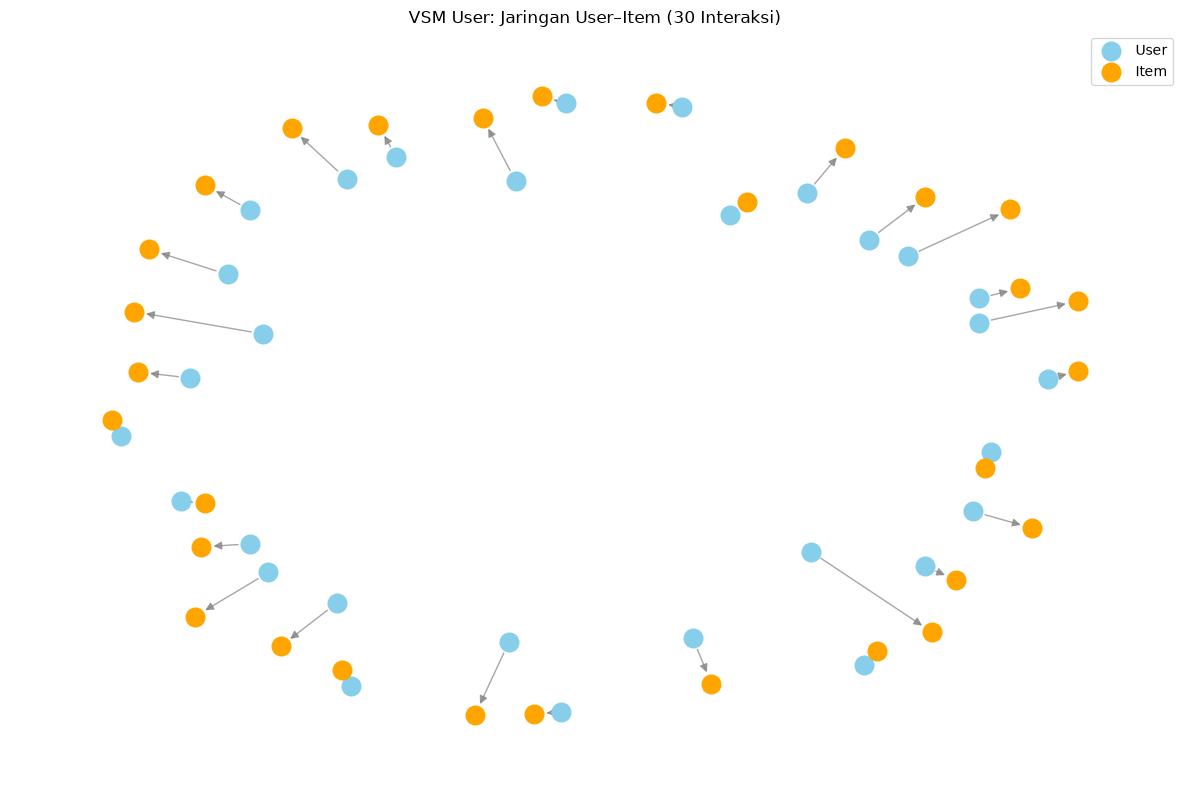

In [118]:
# Membentuk matriks User-Item
row_idx = df_interaksi["visitorid"].map(visitor_to_idx).to_numpy()
col_idx = df_interaksi["itemid"].map(item_to_idx).to_numpy()

user_item_matrix = csr_matrix(
    (
        np.ones(len(df_interaksi), dtype=np.int8),
        (row_idx, col_idx)
    ),
    shape=(len(visitor_ids), len(item_ids))
)

print("=== VSM USER ===")
print("Jumlah User:", len(visitor_ids))
print("Jumlah Item:", len(item_ids))
print("Shape:", user_item_matrix.shape)
print("Jumlah dimensi:", user_item_matrix.ndim)
print("Jumlah interaksi unik (nnz):", user_item_matrix.nnz)
print("Tipe matriks:", type(user_item_matrix).__name__)

# Visualisasi jaringan sampel
plt.figure(figsize=(12, 8))

nx.draw_networkx_edges(
    G_user_item, pos,
    edge_color="gray",
    alpha=0.7,
    width=1,
    arrows=True,
    arrowstyle="-|>",
    arrowsize=12
)

nx.draw_networkx_nodes(
    G_user_item, pos,
    nodelist=user_nodes,
    node_color="skyblue",
    node_size=180,
    label="User"
)

nx.draw_networkx_nodes(
    G_user_item, pos,
    nodelist=item_nodes,
    node_color="orange",
    node_size=180,
    label="Item"
)

plt.title("VSM User: Jaringan User–Item (30 Interaksi)")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

**Interpretasi VSM pada Simpul User**

Matriks User–Item memiliki shape (509.115, 149.709), dengan setiap baris mewakili User dan setiap kolom mewakili Item. Matriks menggunakan format csr_matrix untuk menghemat memori dan memiliki 758.160 pasangan User–Item unik yang berinteraksi. Visualisasi NetworkX menampilkan sampel 30 interaksi, dengan node biru sebagai User, node oranye sebagai Item, dan panah sebagai arah hubungan visual dari User ke Item.

5. **Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!**

=== VSM ITEM ===
Jumlah Item: 149709
Jumlah User: 509115
Shape: (149709, 509115)
Jumlah dimensi: 2
Jumlah interaksi unik (nnz): 758160
Tipe matriks: csr_matrix


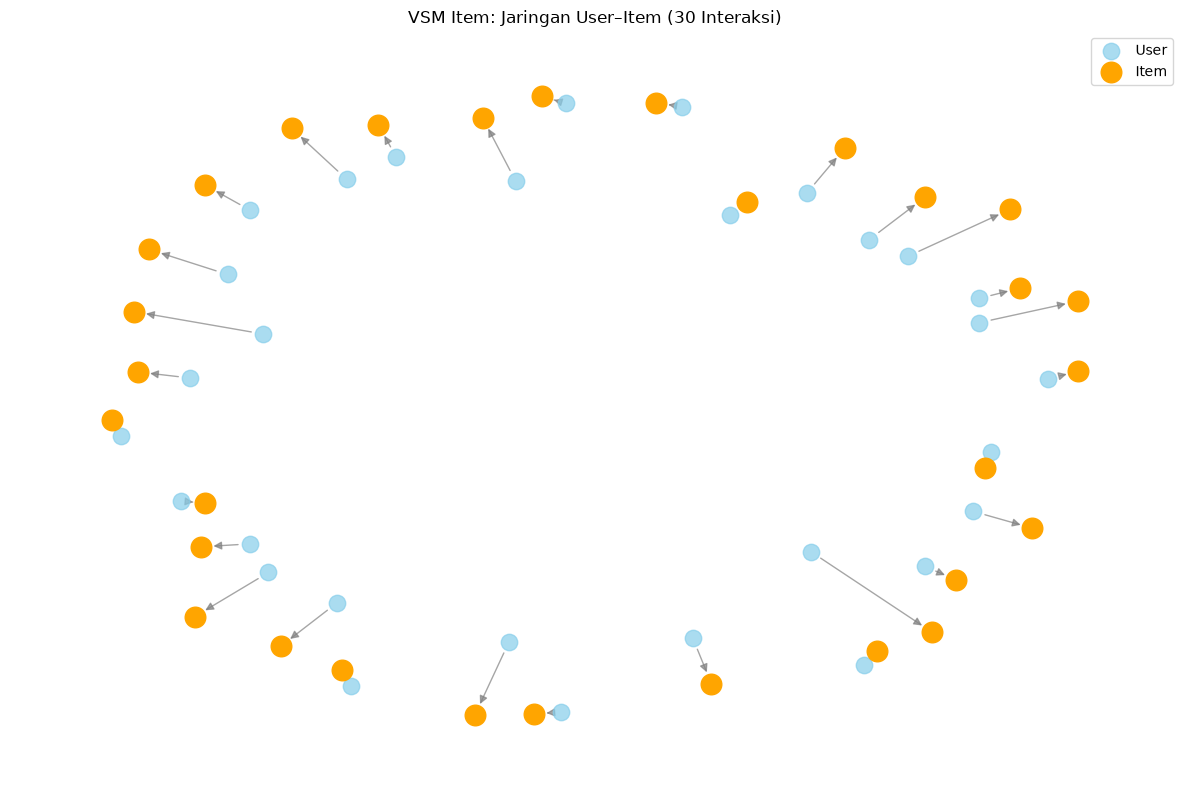

In [119]:
# Membentuk matriks Item-User
row_idx_item = df_interaksi["itemid"].map(item_to_idx).to_numpy()
col_idx_item = df_interaksi["visitorid"].map(visitor_to_idx).to_numpy()

item_user_matrix = csr_matrix(
    (
        np.ones(len(df_interaksi), dtype=np.int8),
        (row_idx_item, col_idx_item)
    ),
    shape=(len(item_ids), len(visitor_ids))
)

print("=== VSM ITEM ===")
print("Jumlah Item:", len(item_ids))
print("Jumlah User:", len(visitor_ids))
print("Shape:", item_user_matrix.shape)
print("Jumlah dimensi:", item_user_matrix.ndim)
print("Jumlah interaksi unik (nnz):", item_user_matrix.nnz)
print("Tipe matriks:", type(item_user_matrix).__name__)

# Visualisasi jaringan yang sama, dengan fokus pada Item
plt.figure(figsize=(12, 8))

nx.draw_networkx_edges(
    G_user_item, pos,
    edge_color="gray",
    alpha=0.7,
    width=1,
    arrows=True,
    arrowstyle="-|>",
    arrowsize=12
)

nx.draw_networkx_nodes(
    G_user_item, pos,
    nodelist=user_nodes,
    node_color="skyblue",
    node_size=140,
    alpha=0.7,
    label="User"
)

nx.draw_networkx_nodes(
    G_user_item, pos,
    nodelist=item_nodes,
    node_color="orange",
    node_size=220,
    label="Item"
)

plt.title("VSM Item: Jaringan User–Item (30 Interaksi)")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

**Interpretasi VSM pada Simpul Item**

Matriks Item–User memiliki shape (149.709, 509.115), dengan setiap baris mewakili Item dan setiap kolom mewakili User. Matriks disimpan dalam format `csr_matrix` dan memiliki 758.160 pasangan interaksi unik. Visualisasi NetworkX menggunakan jaringan bipartit yang sama seperti VSM User, tetapi pembahasan difokuskan pada Item. Perbedaan kedua VSM terletak pada orientasi baris dan kolom matriks, bukan pada hubungan dasar antar-node.

6. **Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!**

Berdasarkan hasil pembentukan Vector Space Modelling (VSM), matriks User memiliki *shape* \((509115, 149709)\), sedangkan matriks Item memiliki *shape* \((149709, 509115)\). Kedua matriks memiliki 758.160 elemen nonzero karena menggunakan pasangan interaksi unik yang sama, tetapi orientasi baris dan kolomnya berbeda.

**Efektivitas.** VSM User lebih sesuai untuk menganalisis kemiripan antarpengguna berdasarkan pola interaksi terhadap item. Sebaliknya, VSM Item lebih sesuai untuk menganalisis kemiripan antaritem berdasarkan pengguna yang berinteraksi dengannya. Efektivitas representasi bergantung pada tujuan analisis.

**Efisiensi.** Jumlah item (149.709) lebih sedikit daripada jumlah user (509.115). Oleh karena itu, VSM Item berpotensi lebih efisien untuk perhitungan kemiripan antaritem menggunakan pendekatan perbandingan berpasangan secara langsung. Penggunaan sparse matrix pada kedua representasi juga membantu menghemat memori karena hanya sebagian kecil pasangan User–Item yang memiliki interaksi.

**Kesimpulan.** VSM Item lebih sesuai jika analisis berfokus pada kemiripan antaritem, sedangkan VSM User lebih sesuai untuk kemiripan antarpengguna. Pemilihan representasi perlu disesuaikan dengan tujuan analisis serta metode perhitungan yang digunakan.

7. **Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python**

In [124]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# 1. Hitung jumlah user yang berinteraksi dengan setiap item
jumlah_user_per_item = np.asarray(
    item_user_matrix.sum(axis=1)
).ravel()

# 2. Pilih item dengan interaksi terbanyak
reference_idx = int(np.argmax(jumlah_user_per_item))
reference_item_id = item_ids[reference_idx]

print("Item acuan:", reference_item_id)
print(
    "Jumlah user yang berinteraksi:",
    int(jumlah_user_per_item[reference_idx])
)

# 3. Hitung cosine similarity item acuan terhadap seluruh item
similarity_scores = cosine_similarity(
    item_user_matrix[reference_idx],
    item_user_matrix
).ravel()

# 4. Keluarkan item acuan itu sendiri
similarity_scores[reference_idx] = -1

# 5. Ambil lima item dengan similarity positif tertinggi
valid_indices = np.where(similarity_scores > 0)[0]

top_indices = valid_indices[
    np.argsort(-similarity_scores[valid_indices])
][:5]

# 6. Buat tabel hasil
top_similar_items = pd.DataFrame({
    "reference_item_id": [reference_item_id] * len(top_indices),
    "similar_item_id": [item_ids[idx] for idx in top_indices],
    "similarity": [similarity_scores[idx] for idx in top_indices]
})

print("\nLima item paling mirip:")
display(top_similar_items)

Item acuan: 5411
Jumlah user yang berinteraksi: 1023

Lima item paling mirip:


,reference_item_id,similar_item_id,similarity
0,5411,33030,0.132696
1,5411,37807,0.093321
2,5411,33956,0.090885
3,5411,193409,0.081281
4,5411,459936,0.078379


**Interpretasi Hasil Cosine Similarity**

Perhitungan cosine similarity dilakukan dengan menggunakan item `5411` sebagai item acuan. Item tersebut dipilih karena memiliki jumlah interaksi pengguna sebanyak 1.023 user. Berdasarkan hasil perhitungan, item `33030` memperoleh nilai kemiripan tertinggi sebesar `0.132696`, diikuti item `37807` sebesar `0.093321`, item `33956` sebesar `0.090885`, item `193409` sebesar `0.081281`, dan item `459936` sebesar `0.078379`.

Hasil tersebut menunjukkan bahwa item `33030` memiliki pola interaksi dengan visitor yang paling mirip terhadap item acuan di antara lima item teratas. Nilai cosine similarity yang lebih tinggi menunjukkan kemiripan vektor interaksi yang lebih besar. Kemiripan ini didasarkan pada pola interaksi visitor terhadap item, bukan pada kesamaan atribut atau deskripsi produk.

(a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!

In [125]:
# Mengubah hasil cosine similarity menjadi list of dictionaries
similarity_records = top_similar_items.to_dict(orient="records")

# Menyimpan relasi SIMILAR_TO ke Neo4j
query_save_similarity = """
UNWIND $records AS row
MATCH (source:Item {itemId: row.reference_item_id})
MATCH (target:Item {itemId: row.similar_item_id})
MERGE (source)-[r:SIMILAR_TO]->(target)
SET r.similarity = row.similarity
RETURN
    source.itemId AS reference_item_id,
    target.itemId AS similar_item_id,
    r.similarity AS similarity
ORDER BY similarity DESC
"""

result, _, _ = driver.execute_query(
    query_save_similarity,
    records=similarity_records,
    database_="retailrocket"
)

print("Hasil similarity yang disimpan ke Neo4j:")
df_saved_similarity = pd.DataFrame([dict(row) for row in result])
display(df_saved_similarity)

Hasil similarity yang disimpan ke Neo4j:


,reference_item_id,similar_item_id,similarity
0,5411,33030,0.132696
1,5411,37807,0.093321
2,5411,33956,0.090885
3,5411,193409,0.081281
4,5411,459936,0.078379


(b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query-nya!

In [126]:
query_top_similarity = """
MATCH (source:Item)-[r:SIMILAR_TO]->(target:Item)
WHERE source.itemId = $reference_item_id
RETURN
    source.itemId AS reference_item_id,
    target.itemId AS similar_item_id,
    r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

result, _, _ = driver.execute_query(
    query_top_similarity,
    reference_item_id=int(reference_item_id),
    database_="retailrocket"
)

df_similarity_neo4j = pd.DataFrame([dict(row) for row in result])

print("Lima item paling mirip yang tersimpan di Neo4j:")
display(df_similarity_neo4j)

Lima item paling mirip yang tersimpan di Neo4j:


,reference_item_id,similar_item_id,similarity
0,5411,33030,0.132696
1,5411,37807,0.093321
2,5411,33956,0.090885
3,5411,193409,0.081281
4,5411,459936,0.078379


8. **Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah
perhitungan similarity!**

**(a) Graf Sebelum Perhitungan Similarity**

Kode Cypher berikut digunakan untuk menampilkan graf interaksi antara Visitor dan Item sebelum penambahan relasi similarity.

```cypher
MATCH (i:Item {itemId: 5411})
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i)
RETURN v, r, i
LIMIT 20
```

**Hasil visualisasi graf:**

![Graf sebelum similarity](sebelum1.png)

**(b) Graf Sesudah Perhitungan Similarity**

Kode Cypher berikut digunakan untuk menampilkan graf interaksi antara Visitor dan Item sesudah penambahan relasi similarity.

```cypher
MATCH (i:Item {itemId: 5411})-[r:SIMILAR_TO]->(similar:Item)
RETURN i, r, similar
ORDER BY r.similarity DESC
LIMIT 5
```

**Hasil visualisasi graf:**

![Graf sebelum similarity](sesudah1.png)

**Analisis**: Sebelum perhitungan similarity, graf memperlihatkan hubungan interaksi antara Visitor dan item 5411. Setelah perhitungan similarity, graf memperlihatkan hubungan kemiripan antara item acuan 5411 dan lima item lainnya. Penambahan relasi SIMILAR_TO memperkaya struktur graf sehingga kemiripan antaritem dapat digunakan dalam analisis rekomendasi.

### **2.2 Analytics**

Pada tahap ini, dilakukan analisis rekomendasi item menggunakan metode K-Nearest Neighbors (KNN). Data training P1 digunakan untuk membangun representasi pola interaksi pengguna dan item, sedangkan data testing P2 digunakan untuk mengevaluasi hasil rekomendasi.

Proses dimulai dengan memilih satu user secara acak menggunakan mekanisme yang dapat direproduksi. Selanjutnya, model KNN digunakan dengan nilai (k=5) untuk menghasilkan rekomendasi item. Hasil rekomendasi kemudian dievaluasi menggunakan metrik Hit@5 dan NDCG@5.

1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu
- tuliskan skrip Python dalam merekomendasikan KNN-nya!
- berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:
- Hit@5
- NDCG@5

In [144]:
import math
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

# ==================================================
# 1. MEMBACA DATA P1 DAN P2
# ==================================================

df_p1 = pd.read_csv("events_P1_training.csv")
df_p2 = pd.read_csv("events_P2_testing.csv")

df_p1["visitorid"] = df_p1["visitorid"].astype(int)
df_p1["itemid"] = df_p1["itemid"].astype(int)
df_p2["visitorid"] = df_p2["visitorid"].astype(int)
df_p2["itemid"] = df_p2["itemid"].astype(int)

# Menggunakan interaksi unik User-Item dari P1
df_interaksi = (
    df_p1[["visitorid", "itemid"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

# ==================================================
# 2. MEMBENTUK USER-ITEM MATRIX
# ==================================================

user_ids = np.sort(df_interaksi["visitorid"].unique())
item_ids = np.sort(df_interaksi["itemid"].unique())

visitor_to_idx = {
    uid: idx for idx, uid in enumerate(user_ids)
}
item_to_idx = {
    iid: idx for idx, iid in enumerate(item_ids)
}

row_idx = df_interaksi["visitorid"].map(visitor_to_idx).to_numpy()
col_idx = df_interaksi["itemid"].map(item_to_idx).to_numpy()

user_item_matrix = csr_matrix(
    (
        np.ones(len(df_interaksi), dtype=np.int8),
        (row_idx, col_idx)
    ),
    shape=(len(user_ids), len(item_ids))
)

# ==================================================
# 3. MEMILIH TARGET USER (SEED 42)
#    Minimal 5 item unik di P1 dan memiliki interaksi P2
# ==================================================

user_interaction_counts = np.asarray(
    user_item_matrix.sum(axis=1)
).ravel()

item_popularity = np.asarray(
    user_item_matrix.sum(axis=0)
).ravel()

shared_item_indices = np.where(item_popularity > 1)[0]

eligible_user_indices = np.unique(
    user_item_matrix[:, shared_item_indices].nonzero()[0]
)

eligible_user_indices = eligible_user_indices[
    user_interaction_counts[eligible_user_indices] >= 5
]

users_p2 = set(df_p2["visitorid"].unique())

eligible_user_indices = np.array([
    idx for idx in eligible_user_indices
    if user_ids[idx] in users_p2
])

if len(eligible_user_indices) == 0:
    raise ValueError(
        "Tidak ditemukan user yang memenuhi kriteria P1 dan P2."
    )

# Acak urutan kandidat secara reproducible
rng = np.random.default_rng(42)
rng.shuffle(eligible_user_indices)

# ==================================================
# 4. KNN (K = 5) DAN PEMILIHAN TARGET
#    Pilih kandidat pertama yang menghasilkan minimal
#    satu item baru dari lima tetangga terdekat.
# ==================================================

target_idx = None
neighbors = None
item_scores = None

for candidate_idx in eligible_user_indices:

    candidate_similarities = cosine_similarity(
        user_item_matrix[candidate_idx],
        user_item_matrix
    ).ravel()

    candidate_similarities[candidate_idx] = -1

    positive_idx = np.where(candidate_similarities > 0)[0]

    nearest_idx = positive_idx[
        np.argsort(candidate_similarities[positive_idx])[::-1]
    ][:5]

    if len(nearest_idx) < 5:
        continue

    candidate_neighbors = pd.DataFrame({
        "visitorid": user_ids[nearest_idx],
        "similarity": candidate_similarities[nearest_idx]
    })

    neighbor_ids = candidate_neighbors["visitorid"].to_numpy()
    neighbor_weights = candidate_neighbors["similarity"].to_numpy()

    weight_map = dict(zip(neighbor_ids, neighbor_weights))

    neighbor_interactions = df_interaksi[
        df_interaksi["visitorid"].isin(neighbor_ids)
    ].copy()

    neighbor_interactions["weight"] = (
        neighbor_interactions["visitorid"].map(weight_map)
    )

    candidate_scores = (
        neighbor_interactions
        .groupby("itemid")["weight"]
        .sum()
        .sort_values(ascending=False)
    )

    candidate_user = int(user_ids[candidate_idx])

    seen_items = set(
        df_interaksi.loc[
            df_interaksi["visitorid"] == candidate_user,
            "itemid"
        ]
    )

    candidate_scores = candidate_scores[
        ~candidate_scores.index.isin(seen_items)
    ]

    if len(candidate_scores) >= 1:
        target_idx = int(candidate_idx)
        neighbors = candidate_neighbors
        item_scores = candidate_scores
        break

if target_idx is None:
    raise ValueError(
        "Tidak ditemukan target dengan lima tetangga dan "
        "minimal satu kandidat item baru."
    )

target_user = int(user_ids[target_idx])

print("Target user:", target_user)
print(
    "Jumlah item unik P1:",
    int(user_interaction_counts[target_idx])
)

# ==================================================
# 5. MENAMPILKAN LIMA TETANGGA TERDEKAT
# ==================================================

print("\nLima tetangga terdekat:")
display(neighbors)

# ==================================================
# 6. HASIL REKOMENDASI
# ==================================================

recommended_top5 = item_scores.head(5)
rec_items = recommended_top5.index.tolist()
top_3_items = rec_items[:3]

print("\nItem rekomendasi yang tersedia:")
display(
    recommended_top5
    .rename_axis("itemid")
    .reset_index(name="score")
)

print("Tiga item rekomendasi:", top_3_items)

# ==================================================
# 7. EVALUASI DENGAN DATA P2
# ==================================================

actual_p2_items = set(
    df_p2.loc[
        df_p2["visitorid"] == target_user,
        "itemid"
    ]
)

hits = [
    int(item in actual_p2_items)
    for item in rec_items
]

# Hit@5
hit_5 = int(sum(hits) > 0)

# DCG@5
dcg = sum(
    hit / math.log2(rank + 1)
    for rank, hit in enumerate(hits, start=1)
)

# IDCG@5
idcg = sum(
    1 / math.log2(rank + 1)
    for rank in range(1, min(len(actual_p2_items), 5) + 1)
)

ndcg_5 = dcg / idcg if idcg > 0 else 0.0

# ==================================================
# 8. HASIL AKHIR
# ==================================================

print("\n========== HASIL ANALISIS 2.2 ==========")
print(f"Target User (Seed 42): {target_user}")
print(f"Lima Item Rekomendasi: {rec_items}")
print(f"Tiga Item Rekomendasi: {top_3_items}")
print(f"Item Aktual P2       : {sorted(actual_p2_items)}")
print(f"Relevansi            : {hits}")
print(f"Hit@5                : {hit_5}")
print(f"NDCG@5               : {ndcg_5:.4f}")


Target user: 1119521
Jumlah item unik P1: 9

Lima tetangga terdekat:


,visitorid,similarity
0,164558,0.471405
1,1137941,0.471405
2,518845,0.471405
3,819488,0.447214
4,50805,0.384900



Item rekomendasi yang tersedia:


,itemid,score
0,14671,0.447214
1,131542,0.447214
2,230720,0.384900


Tiga item rekomendasi: [14671, 131542, 230720]

========== HASIL ANALISIS 2.2 ==========
Target User (Seed 42): 1119521
Lima Item Rekomendasi: [14671, 131542, 230720]
Tiga Item Rekomendasi: [14671, 131542, 230720]
Item Aktual P2       : [83337, 305656]
Relevansi            : [0, 0, 0]
Hit@5                : 0
NDCG@5               : 0.0000


**Rekomendasi Menggunakan K-Nearest Neighbors (KNN)**

Pemilihan user dilakukan secara acak menggunakan seed 42 agar proses dapat direproduksi. User yang terpilih adalah `1119521`, dengan sembilan item unik pada periode training (P1). Metode KNN dengan \(k=5\) dan cosine similarity digunakan untuk mencari lima user dengan pola interaksi paling mirip. Kelima tetangga tersebut adalah user `164558`, `1137941`, `518845`, `819488`, dan `50805`, dengan nilai similarity berturut-turut sebesar 0.471405, 0.471405, 0.471405, 0.447214, dan 0.384900.

Berdasarkan interaksi kelima tetangga tersebut, sistem menghasilkan tiga rekomendasi, yaitu item `14671` dengan skor 0.447214, item `131542` dengan skor 0.447214, dan item `230720` dengan skor 0.384900. Skor diperoleh dari penjumlahan nilai similarity tetangga yang berinteraksi dengan setiap item, setelah item yang sudah pernah diinteraksikan user target pada P1 dikeluarkan dari kandidat rekomendasi.

**Evaluasi Rekomendasi**

Evaluasi menggunakan data testing (P2) menunjukkan bahwa user `1119521` memiliki dua item aktual, yaitu `83337` dan `305656`. Tidak ada satu pun dari tiga item rekomendasi yang cocok dengan item aktual tersebut. Oleh karena itu, diperoleh nilai **Hit@5 sebesar 0** dan **NDCG@5 sebesar 0.0000**. Hasil ini menunjukkan bahwa rekomendasi belum berhasil menemukan item yang relevan bagi user tersebut pada periode testing. Namun, karena evaluasi hanya dilakukan pada satu user, hasil ini belum dapat menggambarkan performa KNN pada keseluruhan dataset.